In [43]:
# lo so è pieno di roba inutile

import numpy as np
import pandas as pd
from itertools import cycle
from matplotlib.path import Path as MplPath
import tifffile
import sys
from pathlib import Path
import plotly.graph_objects as go
from phasorpy.plot import PhasorPlot     # phasor plot stolen from phasorpy 

# personal stuff
import random
import scipy.stats as stats
import matplotlib.pyplot as plt
from iminuit import Minuit, cost

import lib.randgen
import lib.my_stats

# 1. Exponential data generation

In [44]:
τ_true = 3 # ns
N_evt = 10000

tempi = np.random.exponential(scale = τ_true, size=N_evt)
n, xe = np.histogram(tempi, bins='auto')   
    # xe = bin edges, n = bin heights


<h3> Binned NNL fit (only made for comparison purposes)

In [45]:
# CDF F(t) = 1 - e^(-t/tau)
# not using scipy version because I want tau as a parameter
def expon_cdf(x, A, τ):
    return A * τ * (1.0 - np.exp(-x / τ))   # I need cdf for the binned likelihood 


#fixing crazy chi squared results
A_guess, tau_guess = n[0], np.mean(tempi)

c_binned = cost.ExtendedBinnedNLL(n, xe, expon_cdf)
m = Minuit(c_binned, A = A_guess, τ = tau_guess)
m.limits["τ"], m.limits["A"] = (0.001, None), (0.001, None)     # placing lower limits on both parameters to avoid negative values
m.migrad()

print("\n--- Binned Likelihood Fit ---")
# if i dont leave an empty line, params will not display for some reason
display(m.params)

print("\n--- Fit Statistics ---")
lib.my_stats.minuit_stats(m)



--- Binned Likelihood Fit ---


,Name,Value,Hesse Error,Minos Error-,Minos Error+,Limit-,Limit+,Fixed
0,A,3.30e3,0.05e3,,,0.001,,
1,τ,3.029,0.030,,,0.001,,



--- Fit Statistics ---
chi-squared: 70.67
reduced chi-squared: 0.78
dof: 91.00
p-value: 0.94


# 2. Cose serie

Functions for calculating and plotting phasors (given a histogram)

In [46]:
def phasor_calc (n, harm_n = 1):   # given a histogram n (xe), calculates the phasor coordinates G and S

    if add_noise_bool:
        n = add_noise(n, snr_db = 10) 

    fft_vals = np.fft.fft(n)
    fft_norm = fft_vals / fft_vals[0]
    
    G, S = np.real(fft_norm[harm_n]), -np.imag(fft_norm[harm_n])

    return G, S


#######################################################################################################



def data_and_phasor_plot(xe, n, G, S, T_laser):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

    # left panel 
    bin_centers = 0.5 * (xe[:-1] + xe[1:])    # select bin centers

    ax1.hist(tempi, bins = xe, density = False, alpha = 0.3, color = 'steelblue', 
         edgecolor = 'midnightblue', label = 'Data')
    
    ax1.plot(bin_centers, n, color = 'crimson', marker = '', linestyle = '-', 
             linewidth = 1.5)

    ax1.set_xlabel('t (ns)', fontsize = 12)
    ax1.set_ylabel('counts', fontsize = 12)
    #ax1.legend(fontsize = 11, frameon = True, shadow = True)
    ax1.grid(alpha = 0.3)
    ax1.set_xlim(0, xe[-1])

    # right panel
    ω_laser = 1000.0 / T_laser  # Calcolo della frequenza in MHz
    plot = PhasorPlot(frequency = ω_laser, ax = ax2)

    plot.plot([G], [S], marker = 'x', markersize = 10, markeredgewidth = 2, 
              color = 'crimson', label = 'Fasore (Dati)')

    #ax2.legend(loc='upper right', fontsize=11, frameon=True, shadow=True)

    plt.tight_layout()
    plt.show()



###################################################################################################



def add_noise(counts, snr_db):   # snr_db = signal to noise ratio in dB

    rng = np.random.default_rng()   
    snr_linear = 10 ** (snr_db / 10)  # convert SNR from dB to linear scale

    sig_power = np.mean(counts ** 2, axis=0) 
    noise_std = np.sqrt(sig_power / snr_linear)
    noise = rng.standard_normal(counts.shape) * noise_std
    
    return np.clip(counts + noise, 0, None)


Testing phasor, plotting, and noise functions

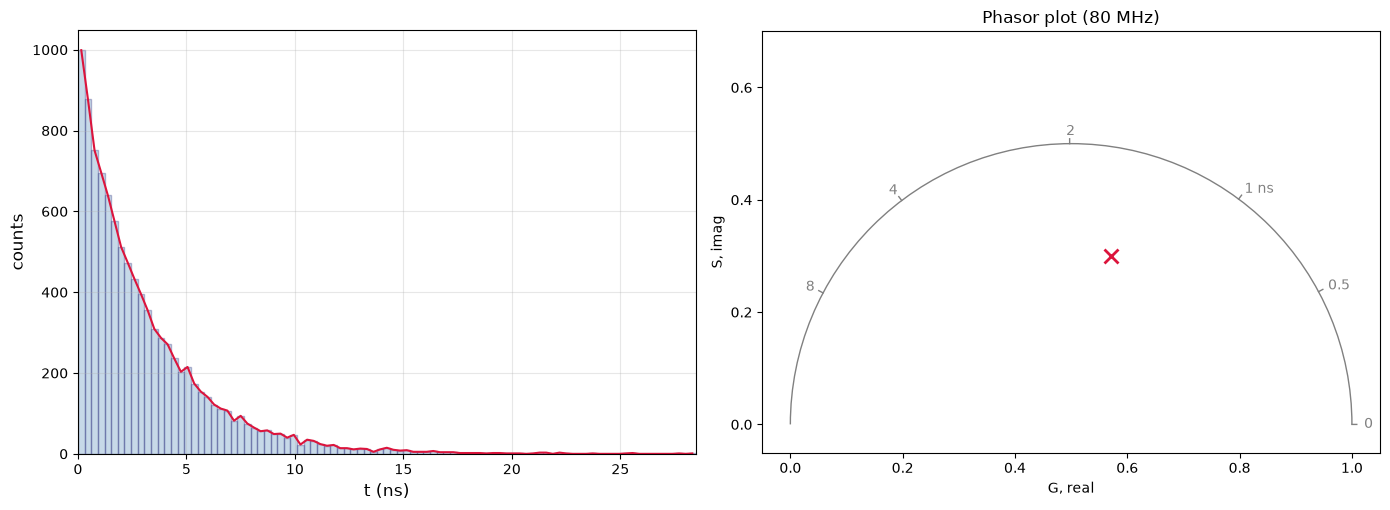

In [48]:

add_noise_bool = True  # set to True to add noise, False to keep original data

phasors = [phasor_calc(n, harm_n) for harm_n in range(1, 4)]  # calculate phasors for the first three harmonics
data_and_phasor_plot(xe, n, phasors[0][0], phasors[0][1], T_laser=12.5)  # [0][1] = first harmonic, S
